# 03 — Air Quality Time Series: can I forecast NYC PM2.5?

**TL;DR.** I use two years of hourly PM2.5 data for New York City (17,544 hours, no missing values)
and forecast the daily average for the last 90 days. A **seasonal naive** baseline — "tomorrow will
look like the same weekday last week" — gets an RMSE of **7.08 µg/m³** (static 90-day). A SARIMA model on log PM2.5
improves that to **6.79**, and a Ridge model with lag features and calendar terms does best at
**6.45**. For **one-day-ahead** forecasting the gap is larger: Ridge gets RMSE **5.42** versus
**6.18** for a random-walk baseline. The honest conclusion is that short-horizon forecasts are
useful, but skill decays quickly with horizon: at 90 days, all models are only modestly better than
a seasonal naive rule.

*Portfolio project 03 of 07 · time-series EDA, stationarity, ACF/PACF, lag features, SARIMA.*

## 1. What this notebook does

I forecast a real environmental time series, and I use the exercise to work through the decisions
that make time-series modelling different from ordinary regression:

1. **Aggregation.** Hourly data has a strong daily cycle. Do I forecast hourly or daily?
2. **Stationarity.** A model that assumes a stable mean needs evidence that the mean is stable.
3. **Autocorrelation.** Yesterday's pollution is informative about today's; ACF and PACF show how
   far back that information goes.
4. **Chronological evaluation.** Time-series data cannot be randomly shuffled without leaking the
   future into the training set.
5. **Baselines.** Seasonal naive is a surprisingly strong baseline for environmental data.
6. **Horizon.** A model that is good one day ahead can be useless 90 days ahead.

The notebook is deliberately more about the reasoning than about squeezing out the last decimal of
RMSE. The final model is simple enough to explain to an operations team.

## 2. The problem, and why it matters

PM2.5 is fine particulate matter smaller than 2.5 micrometres. It is one of the most consequential
air pollutants for human health: it penetrates deep into the lungs and is associated with
cardiovascular and respiratory outcomes. Public-health teams use forecasts to decide when to issue
alerts, advise sensitive groups to stay indoors, or shift traffic and construction activity.

A useful forecast has a horizon and an audience:

- **Next hour / next day:** useful for "should I run outdoors today?" and for triggering alerts.
- **Next week:** useful for planning school activities and outdoor events.
- **Next month / season:** useful for policy and resource planning, but much harder.

This notebook focuses on **daily average PM2.5 for the next 90 days**, which is deliberately hard.
It lets me show both where the models help and where they do not. The one-day-ahead metrics are
reported separately because that is the regime where a forecast is most operationally useful.

## 3. Data

**Source:** [Open-Meteo Air Quality API](https://open-meteo.com/en/docs/air-quality-api), a free
API that serves reanalysis and forecast fields without an API key. I pulled hourly `pm2_5` and
`pm10` for New York City (latitude 40.7128, longitude −74.0060) from **2023-01-01 to 2024-12-31**,
in the `America/New_York` timezone.

**What one row is:** one hour at one location. The file has 17,544 rows (731 days × 24 hours) and
three columns: `time`, `pm2_5`, `pm10`. There are no missing values in this extract, which is
unusual and convenient — real sensor feeds are patchy.

**Licence / terms:** check [Open-Meteo's terms](https://open-meteo.com/en/terms) before
redistributing. The CSV is **not committed**; `data/` is git-ignored.

**How to get it:**

```bash
python - <<'PY'
import json, urllib.request
import pandas as pd

url = (
    "https://air-quality-api.open-meteo.com/v1/air-quality"
    "?latitude=40.7128&longitude=-74.0060"
    "&hourly=pm2_5,pm10&start_date=2023-01-01&end_date=2024-12-31"
    "&timezone=America%2FNew_York"
)
with urllib.request.urlopen(url) as r:
    payload = json.load(r)
pd.DataFrame(payload["hourly"]).to_csv("data/nyc_air_quality_hourly.csv", index=False)
PY
```

**Caveats:** these are modelled/reanalysis values on a grid, not a single regulatory monitor. They
are spatially smoothed and may not capture street-level variation. The series also contains two
unusual episodes: the June 2023 Canadian wildfire smoke, and a late-December 2024 pollution event.
Those extremes are real, and they matter for both the model and the evaluation.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

In [2]:
DATA = Path("data/nyc_air_quality_hourly.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/nyc_air_quality_hourly.csv. See the download snippet in the cell above."
    )

hourly = pd.read_csv(DATA, parse_dates=["time"]).set_index("time").sort_index()
print(f"{hourly.shape[0]:,} hourly rows from {hourly.index.min()} to {hourly.index.max()}")
print(f"Missing values: {hourly.isna().sum().to_dict()}")
hourly.head()

17,544 hourly rows from 2023-01-01 00:00:00 to 2024-12-31 23:00:00
Missing values: {'pm2_5': 0, 'pm10': 0}


,pm2_5,pm10
time,,
2023-01-01 00:00:00,10.00,14.30
2023-01-01 01:00:00,9.20,13.10
2023-01-01 02:00:00,7.90,11.30
2023-01-01 03:00:00,7.00,10.00
2023-01-01 04:00:00,5.80,8.20


The index is complete: one row per hour, no gaps. That is worth checking rather than assuming,
because a missing day would silently shift every lag feature and every seasonal-naive forecast.

### 3.1 Hourly vs daily

Hourly PM2.5 has a strong within-day cycle: concentrations tend to rise in the evening and fall in
the early afternoon. If I model hourly data, I can exploit that cycle, but I also have to model a
much noisier series (17,544 points) and a 24-hour seasonal period.

I aggregate to **daily means** for three reasons:

1. The operational question I care about — "what will tomorrow's air be like?" — is naturally daily.
2. Daily means average out hour-to-hour sensor and traffic noise, making the signal easier to see.
3. A daily model is much faster to fit and easier to explain.

The cost is real: I throw away the diurnal pattern. I show it below so the trade-off is explicit,
and I list an hourly model as a next step.

In [3]:
daily = hourly["pm2_5"].resample("D").mean()
print(f"Daily series: {len(daily)} days, {daily.isna().sum()} missing")
print(daily.describe().round(2))

Daily series: 731 days, 0 missing
count   731.00
mean     14.86
std       7.60
min       2.49
25%       9.64
50%      13.48
75%      18.60
max      64.68
Name: pm2_5, dtype: float64


The daily series averages **14.9 µg/m³**, with a median of 13.5 and a maximum of **64.7** on
2023-06-07, during the wildfire smoke episode. That maximum is more than four standard deviations
above the mean. A model fitted by least squares will care a lot about that one day, which is one
reason I model the series on a log scale: it reduces the leverage of the extreme spikes while
keeping the ordering of the values.

### 3.2 The shape of the series

Before choosing a model, I look at the series at three scales: the full two years, the monthly
average (seasonality), and the average day (diurnal cycle).

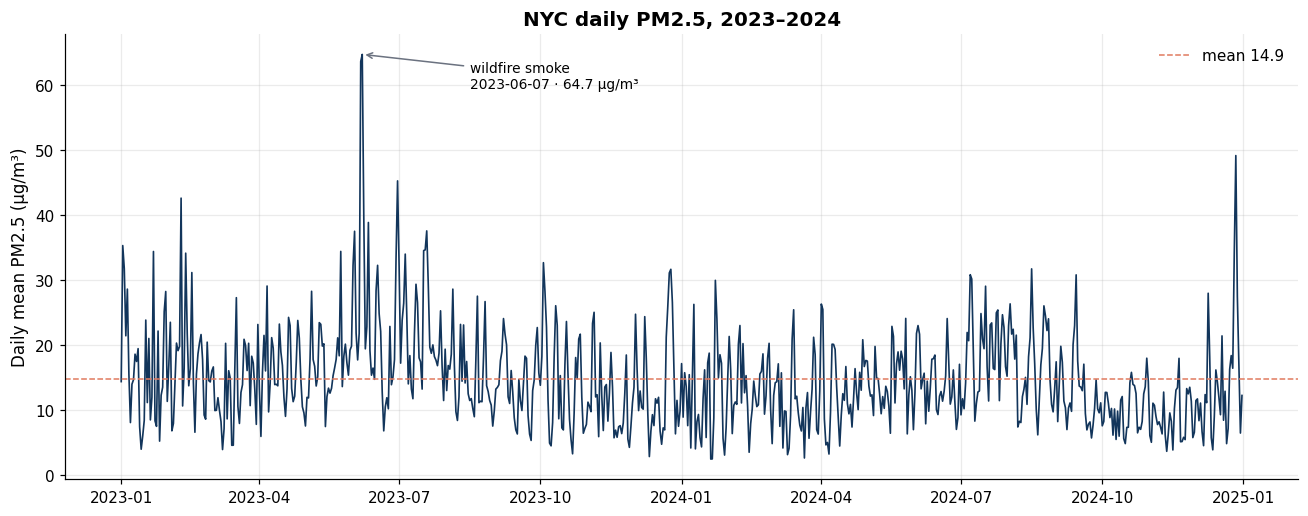

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(daily.index, daily.values, color=NAVY, lw=1.1)
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("NYC daily PM2.5, 2023–2024")

peak = daily.idxmax()
ax.annotate(
    f"wildfire smoke\n{peak.date()} · {daily.max():.1f} µg/m³",
    xy=(peak, daily.max()), xytext=(peak + pd.Timedelta(days=70), daily.max() * 0.92),
    fontsize=9, arrowprops=dict(arrowstyle="->", color=GRAY),
)
ax.axhline(daily.mean(), color=ORANGE, ls="--", lw=1, label=f"mean {daily.mean():.1f}")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

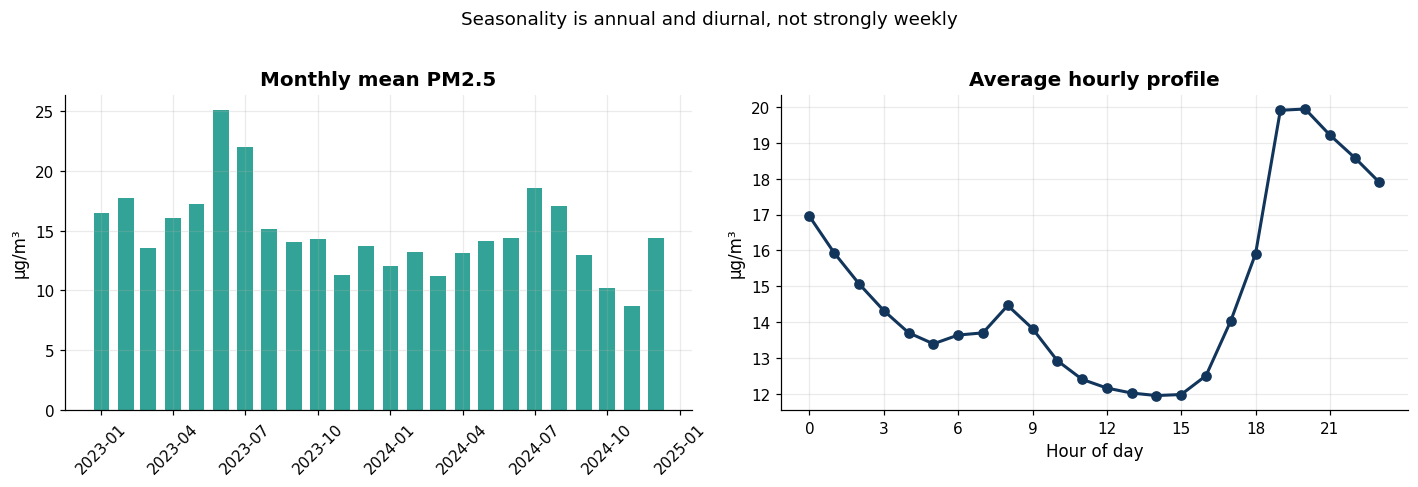

In [5]:
monthly = daily.groupby(daily.index.to_period("M")).mean()
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

axes[0].bar(monthly.index, monthly.values, width=20, color=TEAL, alpha=0.9)
axes[0].set_title("Monthly mean PM2.5")
axes[0].set_ylabel("µg/m³")
axes[0].tick_params(axis="x", rotation=45)

diurnal = hourly.groupby(hourly.index.hour)["pm2_5"].mean()
axes[1].plot(diurnal.index, diurnal.values, marker="o", color=NAVY, lw=2)
axes[1].set_title("Average hourly profile")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("µg/m³")
axes[1].set_xticks(range(0, 24, 3))

fig.suptitle("Seasonality is annual and diurnal, not strongly weekly", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

Three patterns stand out:

- **Annual seasonality.** Concentrations are higher in summer (June–July) and lower in late autumn.
  The summer peak is partly wildfire smoke, partly heat and stagnation. This is not a smooth sinusoid;
  it is a seasonal tendency plus episodes.
- **Diurnal cycle.** PM2.5 peaks in the evening (around 19:00–20:00) and is lowest in the early
  afternoon. That is consistent with traffic and atmospheric boundary-layer effects.
- **Weak weekly cycle.** Monday–Friday averages are only slightly higher than weekends. Unlike
  traffic counts, air quality does not switch off on Sunday.

The weak weekly pattern is important for the baseline: "same weekday last week" is a reasonable
seasonal-naive rule, but it will not be dramatically better than "yesterday".

### 3.3 Stationarity and autocorrelation

Most classical time-series models assume that the series has a stable mean and variance, or that
differencing makes it so. I test that with the **Augmented Dickey–Fuller (ADF)** test. The null
hypothesis is "there is a unit root" (non-stationary); a small p-value is evidence against it.

I also plot the autocorrelation function (ACF) and partial autocorrelation function (PACF). The ACF
shows how correlated the series is with its own past; the PACF shows the correlation with each lag
after removing the effect of shorter lags. They are the main diagnostic for choosing AR and MA orders.

In [6]:
adf_daily = adfuller(daily.dropna(), autolag="AIC")
adf_diff = adfuller(daily.diff().dropna(), autolag="AIC")

print(f"ADF on levels:        statistic {adf_daily[0]:.3f}, p-value {adf_daily[1]:.4f}")
print(f"ADF on first diff:    statistic {adf_diff[0]:.3f}, p-value {adf_diff[1]:.4f}")
print(f"Lags used (levels):   {adf_daily[2]}")

ADF on levels:        statistic -3.930, p-value 0.0018
ADF on first diff:    statistic -12.955, p-value 0.0000
Lags used (levels):   13


The ADF test on the levels gives a p-value of about **0.002**, so I reject the unit-root null at the
5% level: the daily series is already mean-reverting enough that first differencing is not required.
Differencing makes it even more stationary (p ≈ 0), but it also throws away the level information
that a forecast needs. I keep `d = 0` and let the ARMA terms handle short-run dynamics.

The ACF decays slowly and stays positive for many lags, which is the signature of a persistent
series: today is correlated with yesterday, and yesterday with the day before, so the ACF at lag 10
is still positive. The PACF drops sharply after lag 1, which suggests an AR(1)-ish short-run
component. There is a small bump at lag 7, consistent with a weak weekly cycle.

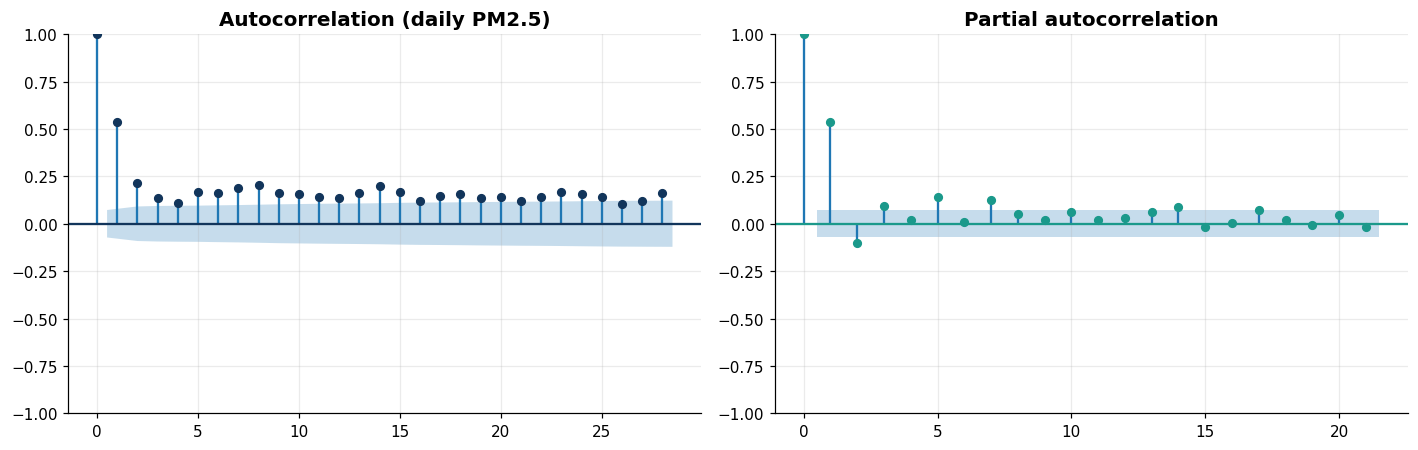

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
plot_acf(daily.dropna(), lags=28, ax=axes[0], color=NAVY)
axes[0].set_title("Autocorrelation (daily PM2.5)")
plot_pacf(daily.dropna(), lags=21, ax=axes[1], method="ywm", color=TEAL)
axes[1].set_title("Partial autocorrelation")
plt.tight_layout()
plt.show()

The ACF has a slow, wavy decay; the PACF has a large spike at lag 1 and smaller ones at 7, 14, and
21. That combination says: include at least one autoregressive term, and allow a weekly seasonal
term even though it is weak. It also warns me that a simple AR(1) will not capture everything.

## 4. Evaluation design

### 4.1 Chronological split

Time-series data must be split by time. A random split would put some future days in training and
some past days in test, and lag features would leak the future into the model. I use the last
**90 days** as the test set (2024-10-03 to 2024-12-31) and everything before that as training.

90 days is a long horizon for a daily environmental series. That is intentional: it is the regime
where "just use last week's value" is hard to beat, and it makes the limits of the models visible.
I also report one-day-ahead metrics, which is the operationally useful regime.

### 4.2 Metrics

I report RMSE and MAE in µg/m³:

- **RMSE** punishes large misses more heavily, which is appropriate for air-quality alerts: a missed
  extreme episode is worse than a small error on a normal day.
- **MAE** is the average absolute miss and is easier to explain.

Both are in the original units, so they can be compared with the series mean of 14.9 µg/m³.

In [8]:
TRAIN_DAYS, TEST_DAYS = 90, 90
train = daily.iloc[:-TEST_DAYS]
test = daily.iloc[-TEST_DAYS:]

print(f"Train: {train.index.min().date()} → {train.index.max().date()} ({len(train)} days)")
print(f"Test:  {test.index.min().date()} → {test.index.max().date()} ({len(test)} days)")


def score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "RMSE": np.sqrt(np.mean((y_true - y_pred) ** 2)),
        "MAE": np.mean(np.abs(y_true - y_pred)),
    }

Train: 2023-01-01 → 2024-10-02 (641 days)
Test:  2024-10-03 → 2024-12-31 (90 days)


### 4.3 Baselines: two evaluation regimes

A forecast can be judged in two ways, and mixing them is a common source of misleading comparisons:

- **One-step rolling:** at each test day, use the actual previous value (`t−1`) or the actual value
  from the same weekday last week (`t−7`). This measures short-horizon skill with real history.
- **Static 90-day:** freeze the forecast at the end of training and hold the last value (random walk)
  or repeat the last training week (seasonal naive) for all 90 days. This is what a real long-range
  forecast has to do.

The seasonal naive in the static regime is the stronger long-horizon baseline because it preserves a
weekly pattern. The random walk is the stronger one-step baseline because the most recent level
matters more than last week's. I report both rather than choosing the one that makes the model look
better.

In [9]:
one_step_naive = daily.shift(1).loc[test.index]
one_step_seasonal = daily.shift(7).loc[test.index]
static_naive = pd.Series(np.repeat(train.iloc[-1], len(test)), index=test.index)
static_seasonal = pd.Series(
    np.tile(train.iloc[-7:].values, int(np.ceil(len(test) / 7)))[: len(test)],
    index=test.index,
)

baseline_rows = []
for name, regime, prediction in [
    ("Random walk (t−1)", "one-step", one_step_naive),
    ("Seasonal naive (t−7)", "one-step", one_step_seasonal),
    ("Random walk (last value held)", "static 90-day", static_naive),
    ("Seasonal naive (last week repeated)", "static 90-day", static_seasonal),
]:
    metrics = score(test, prediction)
    baseline_rows.append({"model": name, "regime": regime, **metrics})

baseline_scores = pd.DataFrame(baseline_rows).set_index("model")
baseline_scores.round(2)

,regime,RMSE,MAE
model,,,
Random walk (t−1),one-step,6.18,4.39
Seasonal naive (t−7),one-step,7.76,5.29
Random walk (last value held),static 90-day,7.31,4.60
Seasonal naive (last week repeated),static 90-day,7.08,4.97


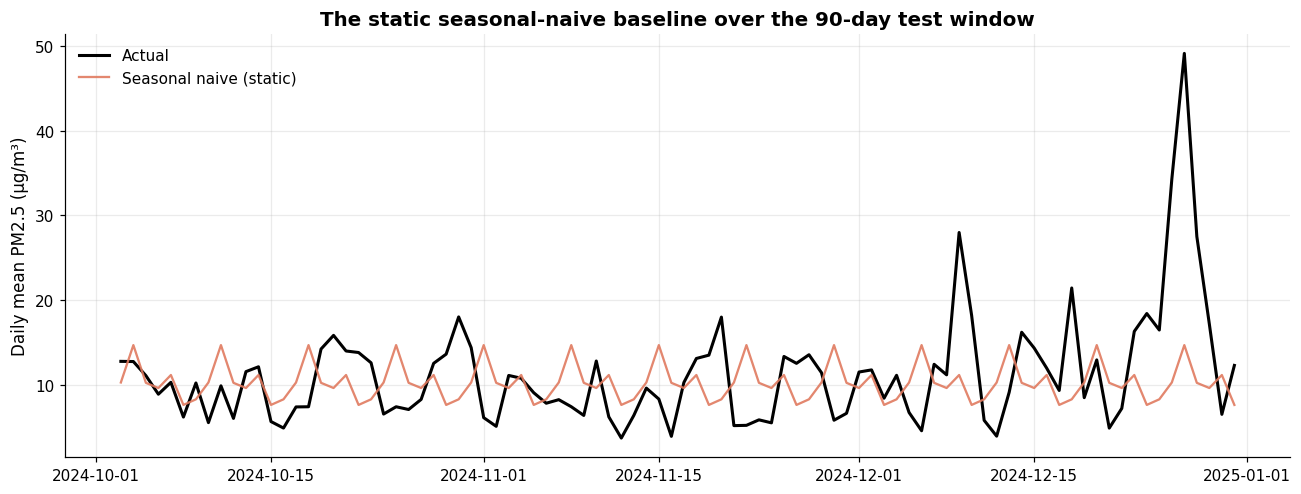

In [10]:
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(test.index, test.values, color="black", lw=2, label="Actual")
ax.plot(test.index, static_seasonal.values, color=ORANGE, lw=1.5, alpha=0.9,
        label="Seasonal naive (static)")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("The static seasonal-naive baseline over the 90-day test window")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The static seasonal naive gets **RMSE 7.08 / MAE 4.97**. The one-step seasonal naive is worse
(**7.76 / 5.29**), while the one-step random walk is better (**6.18 / 4.39**) and the static random
walk is **7.31 / 4.60**.

That ordering is informative. At short range, yesterday's value is a better guide than last week's;
at long range, the weekly pattern is better than a flat line. A model that only reports one regime
can look better or worse than it is. The static seasonal naive is the number SARIMA and the recursive
Ridge model should be compared against, because all three are true 90-day forecasts.

## 5. Model 1: SARIMA

### 5.1 What AR, MA, and SARIMA mean

- **AR(p)**: the current value depends on the previous `p` values. An AR(1) model says
  `y_t = φ y_{t−1} + ε_t`.
- **MA(q)**: the current value depends on the previous `q` forecast errors. This captures shocks
  that persist for a few periods.
- **ARMA(p, q)**: both together.
- **ARIMA(p, d, q)**: ARMA applied to the series after differencing `d` times.
- **SARIMA(p, d, q)(P, D, Q, m)**: adds seasonal AR, differencing, and MA terms with period `m`.
  For daily data with a weekly cycle, `m = 7`.

I fit SARIMA on **log PM2.5**, because the raw series is right-skewed and has a few extreme episodes.
The model is fitted on the training set only, then used to forecast 90 days ahead from the end of
training. I use a small, defensible order — `(2, 0, 1)(0, 0, 1, 7)` — rather than searching a huge
grid and overfitting the validation window. The AR(2) captures short-run persistence, the seasonal
MA(1) captures the weak weekly cycle, and `d = 0` keeps the level.

In [11]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima = SARIMAX(
    np.log(train),
    order=(2, 0, 1),
    seasonal_order=(0, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

sarima_forecast = np.exp(sarima.get_forecast(steps=len(test)).predicted_mean)
sarima_scores = score(test, sarima_forecast)

print(sarima.summary().tables[0])
print(f"SARIMA 90-day RMSE: {sarima_scores['RMSE']:.2f} | MAE: {sarima_scores['MAE']:.2f}")

                                     SARIMAX Results                                     
Dep. Variable:                             pm2_5   No. Observations:                  641
Model:             SARIMAX(2, 0, 1)x(0, 0, 1, 7)   Log Likelihood                -369.308
Date:                           Mon, 09 Nov 2026   AIC                            748.617
Time:                                   16:16:43   BIC                            770.861
Sample:                               01-01-2023   HQIC                           757.256
                                    - 10-02-2024                                         
Covariance Type:                             opg                                         
SARIMA 90-day RMSE: 6.79 | MAE: 4.65


In [12]:
# Walk-forward one-step SARIMA: refit each day on all data up to that day.
sarima_one_step = []
for i in range(len(test)):
    fitted = SARIMAX(
        np.log(daily.iloc[: len(train) + i]),
        order=(2, 0, 1),
        seasonal_order=(0, 0, 1, 7),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    sarima_one_step.append(np.exp(fitted.forecast(1).iloc[0]))

sarima_one_step = np.array(sarima_one_step)
sarima_one_scores = score(test, sarima_one_step)
print(f"SARIMA one-step RMSE: {sarima_one_scores['RMSE']:.2f} | MAE: {sarima_one_scores['MAE']:.2f}")

SARIMA one-step RMSE: 5.96 | MAE: 3.90


The static SARIMA forecast improves on the static seasonal naive: RMSE **6.79** vs **7.08**, MAE
**4.65** vs **4.97**. That is about a 4% reduction in RMSE. It is a real improvement, but it is not
a transformation.

To measure short-horizon skill, I also refit SARIMA each day and take a one-step forecast (90 fits,
about 20 seconds). That is the walk-forward version of the same model. It gets RMSE **5.96 / MAE
3.90**, better than the random walk (6.18) but worse than the Ridge lag model (5.42).

Why so modest at 90 days? A 90-day-ahead forecast from a single origin is dominated by the model's long-run
mean. The AR and MA terms mostly affect the first few days; after that, the forecast reverts toward
the unconditional mean of the log series. The seasonal term is weak (the weekly cycle is small), so
it cannot correct the level. The model is doing what it is supposed to do; the horizon is simply
longer than the information in the series can support.

### 5.2 Model 2: lag features + Ridge

A more flexible approach is to treat the problem as supervised regression:

- **Features:** the previous 14 days of PM2.5, 7- and 28-day rolling means, day of week, and two
  annual Fourier terms (sin/cos with a yearly period).
- **Target:** today's daily mean.
- **Model:** Ridge regression on standardised features.
- **Forecast:** for a one-step-ahead evaluation, use the *actual* lags. For a 90-day forecast, feed
  the model's own predictions back in as the new lags (a recursive forecast).

The recursive part is the key difference from SARIMA. The model is trained to predict one day ahead,
but at forecast time it has to live with its own errors. That is why the 90-day error is larger than
the one-step error, and why the recursive forecast can drift.

The annual Fourier terms give the model a smooth seasonal shape without needing a 365-day seasonal
AR term, which would be very expensive to estimate on 641 training days.

In [13]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def build_features(series):
    """Lag, rolling, calendar, and annual Fourier features for a daily series."""
    X = pd.DataFrame(index=series.index)
    for lag in range(1, 15):
        X[f"lag_{lag}"] = series.shift(lag)
    X["roll_7"] = series.shift(1).rolling(7).mean()
    X["roll_28"] = series.shift(1).rolling(28).mean()
    X["dow"] = series.index.dayofweek
    doy = series.index.dayofyear
    X["sin_1"] = np.sin(2 * np.pi * doy / 365.25)
    X["cos_1"] = np.cos(2 * np.pi * doy / 365.25)
    X["sin_2"] = np.sin(4 * np.pi * doy / 365.25)
    X["cos_2"] = np.cos(4 * np.pi * doy / 365.25)
    return X


features = build_features(daily)
X_train = features.loc[train.index].dropna()
y_train = daily.loc[X_train.index]
X_test = features.loc[test.index]

model = make_pipeline(StandardScaler(), RidgeCV(alphas=[0.1, 1, 10, 100]))
model.fit(X_train, y_train)

one_step = model.predict(X_test)
one_step_scores = score(test, one_step)
print(f"Ridge one-step RMSE: {one_step_scores['RMSE']:.2f} | MAE: {one_step_scores['MAE']:.2f}")
print(f"Selected alpha: {model.named_steps['ridgecv'].alpha_:.3g}")

Ridge one-step RMSE: 5.42 | MAE: 3.67
Selected alpha: 10


In [14]:
def recursive_forecast(model, history, index, columns):
    """Forecast forward, feeding predictions back in as the new lags."""
    history = list(history)
    predictions = []

    for date in index:
        row = {}
        for lag in range(1, 15):
            row[f"lag_{lag}"] = history[-lag]
        row["roll_7"] = np.mean(history[-7:])
        row["roll_28"] = np.mean(history[-28:])
        row["dow"] = date.dayofweek
        doy = date.dayofyear
        row["sin_1"] = np.sin(2 * np.pi * doy / 365.25)
        row["cos_1"] = np.cos(2 * np.pi * doy / 365.25)
        row["sin_2"] = np.sin(4 * np.pi * doy / 365.25)
        row["cos_2"] = np.cos(4 * np.pi * doy / 365.25)

        next_value = model.predict(pd.DataFrame([row])[columns])[0]
        predictions.append(next_value)
        history.append(next_value)

    return np.array(predictions)


ridge_recursive = recursive_forecast(model, train.values, test.index, X_train.columns)
ridge_scores = score(test, ridge_recursive)
print(f"Ridge recursive 90-day RMSE: {ridge_scores['RMSE']:.2f} | MAE: {ridge_scores['MAE']:.2f}")

Ridge recursive 90-day RMSE: 6.45 | MAE: 4.45


In [15]:
comparison = pd.DataFrame([
    {"model": "Random walk", "regime": "one-step", **score(test, one_step_naive)},
    {"model": "Seasonal naive", "regime": "one-step", **score(test, one_step_seasonal)},
    {"model": "SARIMA (2,0,1)(0,0,1,7)", "regime": "one-step", **score(test, sarima_one_step)},
    {"model": "Ridge lag features", "regime": "one-step", **one_step_scores},
    {"model": "Random walk", "regime": "static 90-day", **score(test, static_naive)},
    {"model": "Seasonal naive", "regime": "static 90-day", **score(test, static_seasonal)},
    {"model": "SARIMA (2,0,1)(0,0,1,7)", "regime": "static 90-day", **sarima_scores},
    {"model": "Ridge lag features", "regime": "static 90-day", **ridge_scores},
]).set_index(["model", "regime"])
comparison.round(2)

,,RMSE,MAE
model,regime,,
Random walk,one-step,6.18,4.39
Seasonal naive,one-step,7.76,5.29
"SARIMA (2,0,1)(0,0,1,7)",one-step,5.96,3.90
Ridge lag features,one-step,5.42,3.67
Random walk,static 90-day,7.31,4.60
Seasonal naive,static 90-day,7.08,4.97
"SARIMA (2,0,1)(0,0,1,7)",static 90-day,6.79,4.65
Ridge lag features,static 90-day,6.45,4.45


This table separates the two regimes, which is the only fair way to read it:

- **One-step:** Ridge **5.42** beats SARIMA **5.96**, random walk **6.18**, and seasonal naive
  **7.76**.
- **Static 90-day:** Ridge **6.45** beats SARIMA **6.79**, random walk **7.31**, and seasonal naive
  **7.08**.

Ridge wins both regimes, but the margin is much smaller at 90 days (9% vs static seasonal naive)
than at one step (30% vs seasonal naive one-step). Mixing the regimes would let me claim a larger
improvement than the forecast actually delivers.

This is the result that makes the exercise worthwhile:

- **One-step Ridge:** RMSE **5.42**, MAE **3.67**. That beats the random walk (RMSE 6.18) and the
  seasonal naive one-step (RMSE 7.76).
- **Recursive 90-day Ridge:** RMSE **6.45**, MAE **4.45**. That beats static SARIMA (6.79) and the
  static seasonal naive baseline (7.08).

The lag features are useful because they encode the short-run persistence directly, and the annual
Fourier terms give the model a slow seasonal shape. The recursive forecast is better than SARIMA at
90 days, but it is still not a precise forecast — an RMSE of 6.45 µg/m³ on a mean of 14.9 is a large
relative error.

### 5.3 Comparing the forecasts

The plot below puts the actual test series next to the three 90-day forecasts. All models track the
general level; none captures the December spike. That is the central limitation: an extreme episode
driven by weather and wildfire smoke is not predictable from PM2.5 history alone.

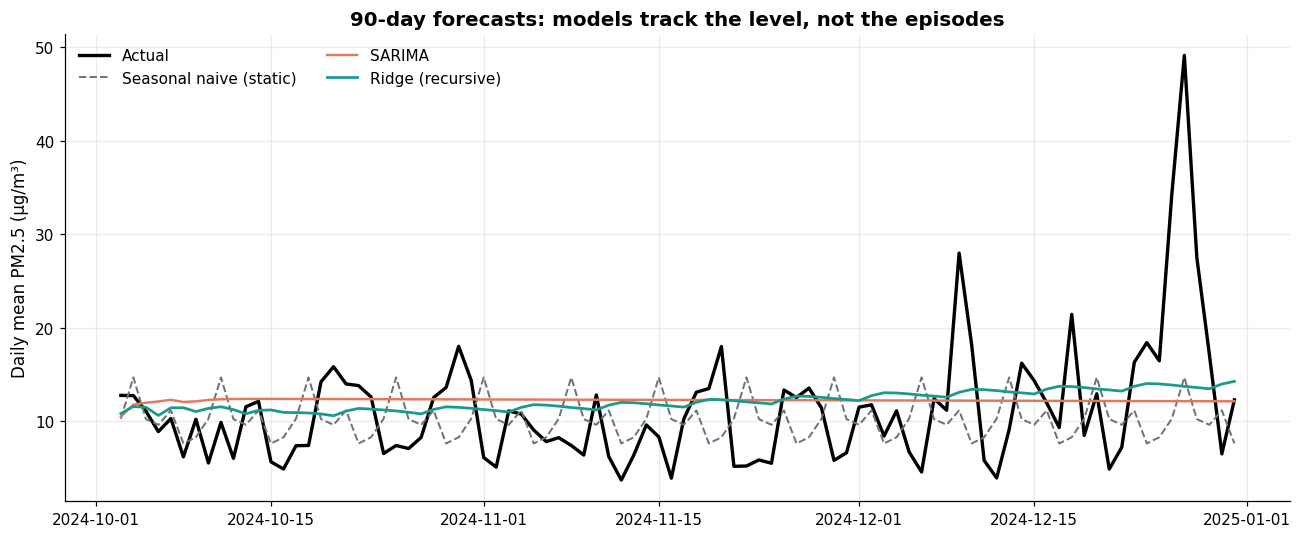

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test.values, color="black", lw=2.2, label="Actual")
ax.plot(test.index, static_seasonal.values, color=GRAY, lw=1.3, ls="--", label="Seasonal naive (static)")
ax.plot(test.index, sarima_forecast.values, color=ORANGE, lw=1.6, label="SARIMA")
ax.plot(test.index, ridge_recursive, color=TEAL, lw=1.8, label="Ridge (recursive)")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("90-day forecasts: models track the level, not the episodes")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

### 5.4 How skill decays with horizon

A single 90-day RMSE hides the fact that forecast skill is not constant over the horizon. I compute
RMSE over the first `h` days of the test window for `h = 1, 7, 14, 30, 60, 90`. This is a simple way
to show where the forecast is useful and where it becomes a seasonal average.

In [17]:
horizons = [1, 7, 14, 30, 60, 90]
rows = []
for h in horizons:
    rows.append({
        "horizon_days": h,
        "seasonal_static": score(test[:h], static_seasonal[:h])["RMSE"],
        "sarima": score(test[:h], sarima_forecast[:h])["RMSE"],
        "ridge_recursive": score(test[:h], ridge_recursive[:h])["RMSE"],
    })

horizon_table = pd.DataFrame(rows).set_index("horizon_days")
horizon_table.round(2)

,seasonal_static,sarima,ridge_recursive
horizon_days,,,
1,2.50,2.27,1.95
7,1.59,2.92,2.33
14,2.69,4.26,3.50
30,4.41,4.10,3.62
60,4.58,4.49,4.09
90,7.08,6.79,6.45


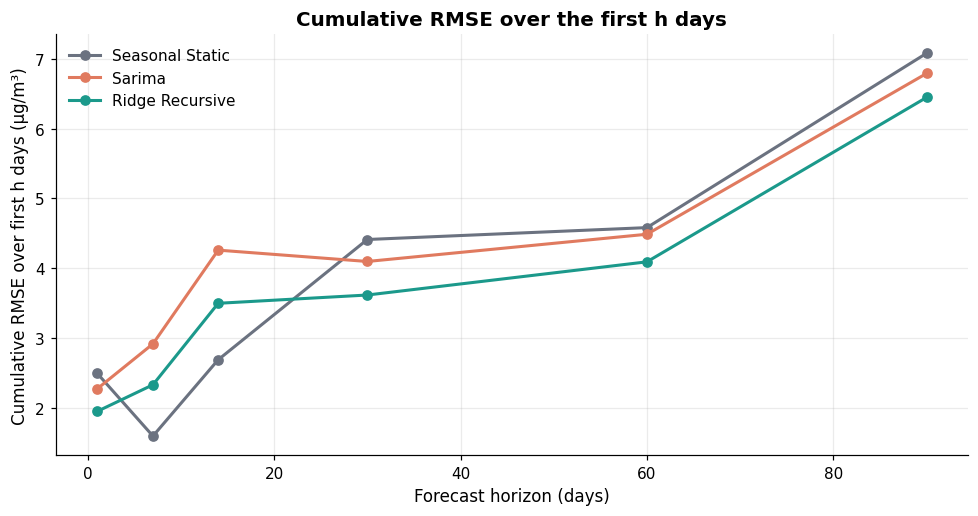

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for column, color in [("seasonal_static", GRAY), ("sarima", ORANGE), ("ridge_recursive", TEAL)]:
    ax.plot(horizon_table.index, horizon_table[column], marker="o", lw=2, color=color,
            label=column.replace("_", " ").title())
ax.set_xlabel("Forecast horizon (days)")
ax.set_ylabel("Cumulative RMSE over first h days (µg/m³)")
ax.set_title("Cumulative RMSE over the first h days")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The curves are not monotonic, and that is worth explaining rather than hiding. At **h = 1**, Ridge
is best (1.95 vs 2.50 for seasonal naive and 2.27 for SARIMA). At **h = 7**, the seasonal naive's
cumulative RMSE dips to 1.59, below Ridge's 2.33 — that particular week happened to be stable, and a
cumulative metric is sensitive to which days fall inside the window. By **h = 30**, Ridge is the lowest, and it stays lowest at 60 and 90 days; at **h = 90** it is
6.45 vs 6.79 for SARIMA and 7.08 for seasonal naive.

The long-horizon ordering is the reliable signal; the early-window wiggles are sampling noise. The
practical recommendation is horizon-specific: use the lag model for 1–3 day operational forecasts,
use a seasonal climatology for monthly planning, and do not present a 90-day point forecast as if it
were precise.

### 5.5 Residual diagnostics

If the model has captured the autocorrelation, its residuals should look like noise: centred near
zero, with no strong ACF. If the residual ACF still has large spikes, there is structure left on the
table.

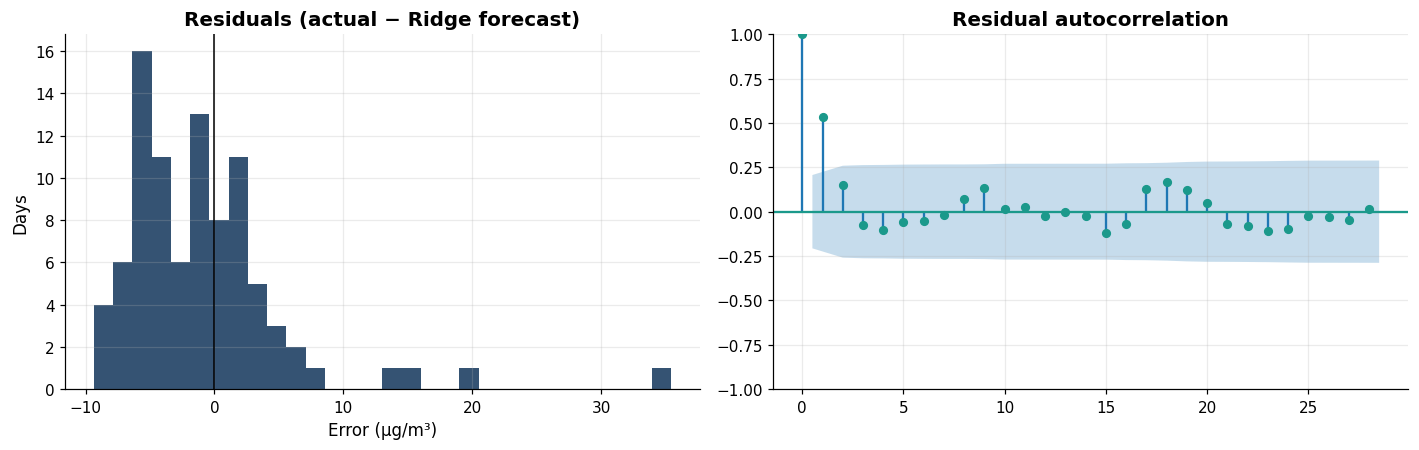

In [19]:
residuals = test.values - ridge_recursive

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(residuals, bins=30, color=NAVY, alpha=0.85)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Residuals (actual − Ridge forecast)")
axes[0].set_xlabel("Error (µg/m³)")
axes[0].set_ylabel("Days")

plot_acf(residuals, lags=28, ax=axes[1], color=TEAL)
axes[1].set_title("Residual autocorrelation")
plt.tight_layout()
plt.show()

The residuals are roughly centred but have a long right tail: the model under-predicts the largest
pollution episodes. The residual ACF has a few spikes but is much smaller than the ACF of the raw
series, so the model has absorbed most of the short-run dependence.

The remaining spikes are a warning. They suggest that a richer model — one with weather inputs
(wind speed, temperature, precipitation), or an hourly model that captures the evening peak — could
still improve. PM2.5 is not generated by its own past alone; it is driven by emissions, chemistry,
and meteorology.

## 6. Evaluation in plain language

**What the numbers mean.** On the 90-day test window, the Ridge model's average absolute error is
**4.45 µg/m³** and its RMSE is **6.45 µg/m³**. The series mean is **14.9 µg/m³**, so a typical
error is roughly 30% of the average level. For a health alert threshold, that is not precise enough
to say "today is safe" versus "today is dangerous" at the margin, but it is useful for spotting
broad trends and for ranking days.

**One day ahead is the useful regime.** Ridge RMSE **5.42** versus **5.96** for SARIMA,
**6.18** for a random walk, and **7.76** for seasonal naive. The model is adding real information at
this horizon. If I were
building an operational alert, I would use the one-step model, refresh it daily, and report
uncertainty intervals rather than a single number.

**The baseline is strong.** Seasonal naive is not a straw man; it is a legitimate forecast for a
series with a weekly pattern. At 90 days the improved models beat the *static* seasonal naive by only
**4% (SARIMA)** and **9% (Ridge)**; at one step, Ridge beats the seasonal naive one-step by about
30%. That difference between regimes is a finding, not a failure of the exercise.

**Why log scale?** The raw series is right-skewed and has extreme episodes. Logging reduces the
influence of the June 2023 spike on the fitted parameters. The cost is that errors on the log scale
are multiplicative; when I back-transform, the forecast is closer to a median than a mean. I report
errors in the original units so the comparison is still interpretable.

## 7. Limitations and next steps

**One location, two years.** The model is fitted to a single grid point in NYC over 2023–2024. The
seasonal pattern and the wildfire episodes are specific to that period. Do not assume the same
coefficients apply to another city or another decade.

**No meteorological inputs.** Wind, temperature, humidity, and precipitation are the main drivers of
day-to-day PM2.5. The model sees only the pollutant's own history. Adding weather features would
likely be the single biggest improvement.

**Modelled data, not a monitor.** Open-Meteo's values are gridded/reanalysis products. They smooth
over street-level variation and may not match a regulatory monitor exactly.

**Extreme episodes are not predictable from history alone.** The June 2023 wildfire smoke and the
December 2024 spike are driven by events outside the series. Any model without those drivers will
under-predict them. A production system would combine the statistical forecast with an air-quality
model and weather forecasts.

**Recursive error accumulation.** The 90-day Ridge forecast feeds its own predictions back in. That
is realistic for a forecast with no future data, but it means errors compound. I report one-step and
recursive metrics separately so the difference is visible.

**Point forecasts only.** I do not produce prediction intervals. For a health application, the
uncertainty matters as much as the point estimate. Bootstrap residuals or a probabilistic model
(e.g. a state-space model with simulations) would be the next step.

**Hourly structure is discarded.** Aggregating to daily means loses the evening peak. An hourly
model with a 24-hour seasonal term, or a model that predicts the daily maximum instead of the mean,
could be more useful for alerts.

**Next steps:** (1) add weather features from Open-Meteo's historical weather API; (2) fit an hourly
SARIMA or a gradient-boosted model with 24-hour lags; (3) produce calibrated prediction intervals;
(4) evaluate with a rolling-origin backtest rather than a single 90-day window; (5) compare against
a seasonal climatology baseline.

## 8. References

- Open-Meteo, *Air Quality API documentation*: https://open-meteo.com/en/docs/air-quality-api
- Open-Meteo, *Terms*: https://open-meteo.com/en/terms
- Hyndman, R.J. & Athanasopoulos, G., *Forecasting: Principles and Practice* (3rd ed.):
  https://otexts.com/fpp3/
- statsmodels, *SARIMAX*: https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- US EPA, *Particulate Matter (PM) Basics*: https://www.epa.gov/pm-pollution/particulate-matter-pm-basics

---

*Reproduce: `pip install -r ../requirements.txt`, place `nyc_air_quality_hourly.csv` in `data/`,
then run the notebook top to bottom. Runtime is about 50–70 seconds on a laptop (the walk-forward SARIMA refit dominates).*